# Combined Sentiment-Intent Classification
### Single-head model predicting joint labels like `neutral_complaint`, `positive_feedback`

---

## Architecture Overview

Instead of two separate heads (one for sentiment, one for intent), we:
1. **Combine** `sentiment` + `intent` into a single string label (e.g. `"neutral_complaint"`)
2. **Encode** those combined labels as class indices
3. **Train** a single softmax classification head on XLM-RoBERTa

```
Input Text
    ↓
XLM-RoBERTa [CLS] token
    ↓
Shared Trunk: Linear(768→512) → GELU → Dropout
              Linear(512→256) → GELU → Dropout
    ↓
Single Classifier: Linear(256 → N_combined_classes)
    ↓
Softmax → Combined Label (e.g. "neutral_complaint")
```

---
## Section 1 — Install & Imports

In [1]:
# Install dependencies (run once on Kaggle / Colab)
!pip install transformers datasets scikit-learn --quiet

In [2]:
import os
import re
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4


---
## Section 2 — Configuration

In [3]:
# ── Paths ──────────────────────────────────────────────────────────────────
DATA_PATH      = "/kaggle/input/datasets/thiwankachanditha/sentiment-intent-predicted/sentiment_intent_predicted_1000.csv"
MODEL_SAVE_DIR = "/kaggle/working/saved_model_combined"
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

# ── Model ──────────────────────────────────────────────────────────────────
ENCODER_NAME = "xlm-roberta-base"
MAX_LEN      = 128
DROPOUT      = 0.3

# ── Training ───────────────────────────────────────────────────────────────
BATCH_SIZE   = 16
EPOCHS       = 15
LR           = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1          # 10% of total steps used for LR warm-up
VAL_SPLIT    = 0.15
SEED         = 42

# ── Rare-class threshold ───────────────────────────────────────────────────
# Combined labels with fewer than this many samples will be dropped
MIN_SAMPLES  = 5

# ── Device ─────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

torch.manual_seed(SEED)
np.random.seed(SEED)

Device: cuda


---
## Section 3 — Load & Explore Data

In [4]:
df = pd.read_csv(DATA_PATH)
df.rename(columns={
    'Sentence'  : 'text',
    'intent'    : 'intent_label',
    'sentiment' : 'sentiment_label'
}, inplace=True)

print(f"Total samples : {len(df)}")
print(f"Columns       : {list(df.columns)}")
df.head()

Total samples : 1000
Columns       : ['Unnamed: 0', 'text', 'Sinhala_Generated', 'english_text', 'intent_label', 'confidence', 'sentiment_label']


,Unnamed: 0,text,Sinhala_Generated,english_text,intent_label,confidence,sentiment_label
0,0,ma padikam puro puro enna goba wahansala bakan...,මා පදිකම් පුරෝ පුරෝ එන්න ගොබ වහන්සල බකන් නිලාන...,"I've been walking all the way down the street,...",Complaint,0.99,Neutral
1,1,nawa gilunath ban chuun,නවා ගිලුනත් බණ චූන්,The newly swallowed bun Chun.,Complaint,0.97,Negative
2,2,usaviyata ihalin gihin marapu pirisa 60 kata v...,උසවියට ඉහළින් ගිහින් මරපු පිරිස 60 කට වෑඩී අහි...,The 60 people who went up to the high court an...,Complaint,0.99,Neutral
3,3,proud to be a sri lankan😜😜😀😀,ප්‍රොඋද් ටො බී අ සාරි ලන්කන්😜😜😀😀,Produced to be a Sarah Lincoln😜😜😀😀,Greeting,0.99,Neutral
4,4,hama gedarakama oya prashne amma kenek wela ma...,හම ගෙදරකම ඔය ප්‍රශ්නේ අම්මා කෙනෙක් වෙලා මටත් ප...,"Every day at home, the same problem arises as ...",Complaint,0.99,Neutral


In [5]:
print("Sentiment distribution:")
print(df['sentiment_label'].value_counts(), "\n")

print("Intent distribution:")
print(df['intent_label'].value_counts())

Sentiment distribution:
sentiment_label
Neutral     673
Negative    314
Positive     13
Name: count, dtype: int64 

Intent distribution:
intent_label
Complaint     752
Greeting      108
Inquiry        88
Feedback       29
Suggestion     18
Other           5
Name: count, dtype: int64


---
## Section 4 — Create Combined Labels

In [6]:
# ── 4.1  Build combined label: "<sentiment>_<intent>" ─────────────────────
df['combined_label'] = (
    df['sentiment_label'].str.strip().str.lower() + '_' +
    df['intent_label'].str.strip().str.lower()
)

print("All combined labels and their counts:")
counts = df['combined_label'].value_counts()
print(counts, "\n")

# ── 4.2  Drop rare combinations (< MIN_SAMPLES) ───────────────────────────
rare = counts[counts < MIN_SAMPLES].index.tolist()
if rare:
    print(f"Dropping rare labels (< {MIN_SAMPLES} samples): {rare}")
    df = df[~df['combined_label'].isin(rare)].reset_index(drop=True)
    print(f"Remaining samples: {len(df)}")
else:
    print("No rare labels to drop.")

# ── 4.3  Encode labels ────────────────────────────────────────────────────
le = LabelEncoder()
df['label'] = le.fit_transform(df['combined_label'])

COMBINED_CLASSES = list(le.classes_)
NUM_CLASSES      = len(COMBINED_CLASSES)
print(f"\nFinal classes ({NUM_CLASSES}):")
for i, c in enumerate(COMBINED_CLASSES):
    print(f"  [{i}] {c}")

All combined labels and their counts:
combined_label
neutral_complaint      513
negative_complaint     234
neutral_greeting        75
neutral_inquiry         64
negative_greeting       29
negative_inquiry        20
neutral_feedback        15
negative_feedback       14
negative_suggestion     12
neutral_suggestion       6
positive_complaint       5
negative_other           5
positive_inquiry         4
positive_greeting        4
Name: count, dtype: int64 

Dropping rare labels (< 5 samples): ['positive_inquiry', 'positive_greeting']
Remaining samples: 992

Final classes (12):
  [0] negative_complaint
  [1] negative_feedback
  [2] negative_greeting
  [3] negative_inquiry
  [4] negative_other
  [5] negative_suggestion
  [6] neutral_complaint
  [7] neutral_feedback
  [8] neutral_greeting
  [9] neutral_inquiry
  [10] neutral_suggestion
  [11] positive_complaint


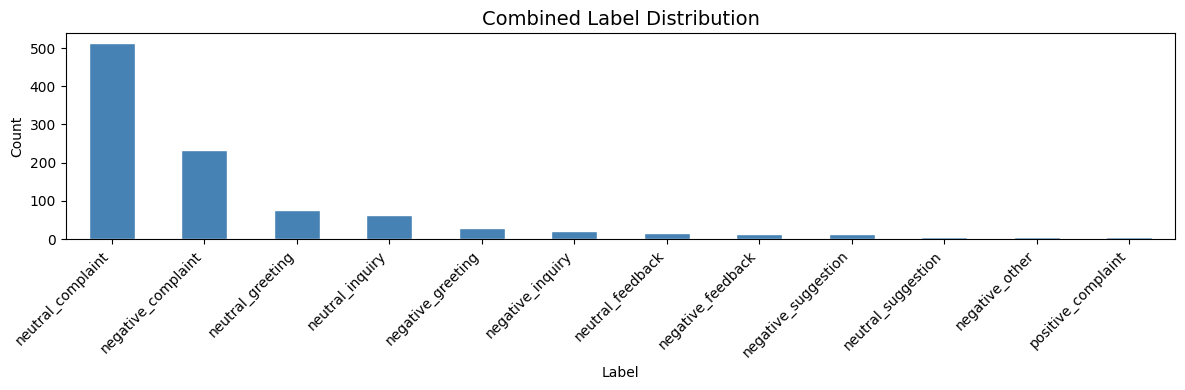

In [7]:
# ── 4.4  Visualise combined label distribution ────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
df['combined_label'].value_counts().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Combined Label Distribution', fontsize=14)
ax.set_xlabel('Label')
ax.set_ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## Section 5 — Text Preprocessing

In [8]:
def clean_text(text: str) -> str:
    """Light normalisation — keep Sinhala unicode, strip noise."""
    text = str(text)
    text = re.sub(r'http\S+|www\.\S+', '', text)   # URLs
    text = re.sub(r'@\w+', '', text)                # mentions
    text = re.sub(r'#\w+', '', text)                # hashtags
    text = re.sub(r'[^\w\s\u0D80-\u0DFF!?.,]', ' ', text)  # keep Sinhala block
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['text'] = df['text'].apply(clean_text)
print("Sample cleaned texts:")
df[['text', 'combined_label']].head(8)

Sample cleaned texts:


,text,combined_label
0,ma padikam puro puro enna goba wahansala bakan...,neutral_complaint
1,nawa gilunath ban chuun,negative_complaint
2,usaviyata ihalin gihin marapu pirisa 60 kata v...,neutral_complaint
3,proud to be a sri lankan,neutral_greeting
4,hama gedarakama oya prashne amma kenek wela ma...,neutral_complaint
5,salli gara ganna wadak dan pvt limited kiyala ...,negative_complaint
6,hehe mage username ekai comment dana widihai c...,neutral_greeting
7,hehe police ballanage neethiya kohomada niwata...,negative_feedback


---
## Section 6 — Train / Validation Split

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    df['text'].tolist(),
    df['label'].tolist(),
    test_size=VAL_SPLIT,
    random_state=SEED,
    stratify=df['label']   # preserve class balance
)

print(f"Train samples : {len(X_train)}")
print(f"Val   samples : {len(X_val)}")

Train samples : 843
Val   samples : 149


---
## Section 7 — Dataset & DataLoader

In [10]:
tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)

class SinhalaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids'     : enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'label'         : torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = SinhalaDataset(X_train, y_train, tokenizer, MAX_LEN)
val_dataset   = SinhalaDataset(X_val,   y_val,   tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Train batches : 53
Val   batches : 10


---
## Section 8 — Model Definition

In [11]:
class CombinedLabelClassifier(nn.Module):
    """
    XLM-RoBERTa + shared trunk + single classification head.

    Trunk mirrors the original multi-head architecture so the encoder
    weights are compatible with any pre-trained joint_heads.pt checkpoint.
    """
    def __init__(self, encoder_name: str, num_classes: int, dropout: float = 0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(encoder_name)
        hidden = self.encoder.config.hidden_size  # 768

        self.trunk = nn.Sequential(
            nn.Linear(hidden, 512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512,    256), nn.GELU(), nn.Dropout(dropout),
        )
        # Single head over all combined classes
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, input_ids, attention_mask):
        # [CLS] representation
        cls = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state[:, 0]          # shape: (B, 768)
        feat   = self.trunk(cls)           # shape: (B, 256)
        logits = self.classifier(feat)     # shape: (B, num_classes)
        return logits


model = CombinedLabelClassifier(ENCODER_NAME, NUM_CLASSES, DROPOUT).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params    : {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total params    : 278,571,788
Trainable params: 278,571,788


---
## Section 9 — Loss, Optimiser & Scheduler

In [12]:
# ── Class-weighted loss to handle imbalance ────────────────────────────────
label_counts = df['label'].value_counts().sort_index().values
class_weights = 1.0 / torch.tensor(label_counts, dtype=torch.float)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES   # normalise
class_weights = class_weights.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
print("Class weights:", {COMBINED_CLASSES[i]: round(float(w), 4) for i, w in enumerate(class_weights)})

# ── Optimiser ─────────────────────────────────────────────────────────────
# Lower LR for encoder, higher for trunk + head (discriminative fine-tuning)
optimizer = torch.optim.AdamW([
    {'params': model.encoder.parameters(),    'lr': LR,       'weight_decay': WEIGHT_DECAY},
    {'params': model.trunk.parameters(),      'lr': LR * 10,  'weight_decay': WEIGHT_DECAY},
    {'params': model.classifier.parameters(), 'lr': LR * 10,  'weight_decay': 0.0},
])

# ── Linear warm-up + linear decay scheduler ───────────────────────────────
total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler    = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

print(f"\nTotal steps  : {total_steps}")
print(f"Warmup steps : {warmup_steps}")

Class weights: {'negative_complaint': 0.0565, 'negative_feedback': 0.9442, 'negative_greeting': 0.4558, 'negative_inquiry': 0.661, 'negative_other': 2.6439, 'negative_suggestion': 1.1016, 'neutral_complaint': 0.0258, 'neutral_feedback': 0.8813, 'neutral_greeting': 0.1763, 'neutral_inquiry': 0.2066, 'neutral_suggestion': 2.2032, 'positive_complaint': 2.6439}

Total steps  : 795
Warmup steps : 79


---
## Section 10 — Training Loop

In [13]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch in loader:
        ids  = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        lbls = batch['label'].to(device)

        optimizer.zero_grad()
        logits = model(ids, mask)
        loss   = criterion(logits, lbls)
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds = logits.argmax(-1)
        correct += (preds == lbls).sum().item()
        total   += lbls.size(0)

    return total_loss / len(loader), correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for batch in loader:
        ids  = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        lbls = batch['label'].to(device)

        logits = model(ids, mask)
        loss   = criterion(logits, lbls)

        total_loss += loss.item()
        preds = logits.argmax(-1)
        correct += (preds == lbls).sum().item()
        total   += lbls.size(0)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(lbls.cpu().tolist())

    return total_loss / len(loader), correct / total, all_preds, all_labels


# ── Training ──────────────────────────────────────────────────────────────
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc   = 0.0
best_model_path = os.path.join(MODEL_SAVE_DIR, "best_combined_model.pt")

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, DEVICE)
    vl_loss, vl_acc, _, _ = evaluate(model, val_loader, criterion, DEVICE)

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)

    flag = ''
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(model.state_dict(), best_model_path)
        flag = '  ← best'

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | "
          f"Val Loss: {vl_loss:.4f}  Acc: {vl_acc:.4f}{flag}")

print(f"\nBest Val Accuracy: {best_val_acc:.4f}")

Epoch 01/15 | Train Loss: 2.4828  Acc: 0.1530 | Val Loss: 2.4824  Acc: 0.2349  ← best
Epoch 02/15 | Train Loss: 2.4856  Acc: 0.2100 | Val Loss: 2.4606  Acc: 0.2349
Epoch 03/15 | Train Loss: 2.4089  Acc: 0.3488 | Val Loss: 2.7906  Acc: 0.5168  ← best
Epoch 04/15 | Train Loss: 2.4181  Acc: 0.1827 | Val Loss: 2.4118  Acc: 0.0872
Epoch 05/15 | Train Loss: 2.4145  Acc: 0.2622 | Val Loss: 2.3242  Acc: 0.2148
Epoch 06/15 | Train Loss: 2.4316  Acc: 0.2017 | Val Loss: 2.4165  Acc: 0.2953
Epoch 07/15 | Train Loss: 2.4128  Acc: 0.2681 | Val Loss: 2.4654  Acc: 0.1879
Epoch 08/15 | Train Loss: 2.5467  Acc: 0.2159 | Val Loss: 2.4558  Acc: 0.2349
Epoch 09/15 | Train Loss: 2.4799  Acc: 0.2788 | Val Loss: 2.4418  Acc: 0.5034
Epoch 10/15 | Train Loss: 2.4021  Acc: 0.3274 | Val Loss: 2.3159  Acc: 0.5034
Epoch 11/15 | Train Loss: 2.3224  Acc: 0.1910 | Val Loss: 2.3048  Acc: 0.4966
Epoch 12/15 | Train Loss: 2.3041  Acc: 0.3369 | Val Loss: 2.3288  Acc: 0.5168
Epoch 13/15 | Train Loss: 2.2875  Acc: 0.2847 | 

---
## Section 11 — Training Curves

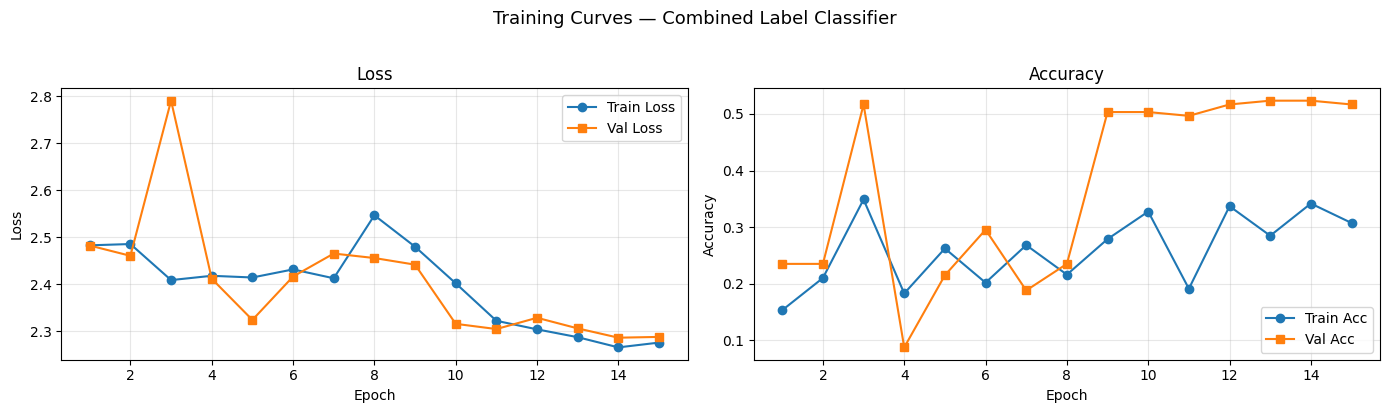

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
ax1.plot(epochs_range, history['val_loss'],   label='Val Loss',   marker='s')
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history['train_acc'], label='Train Acc', marker='o')
ax2.plot(epochs_range, history['val_acc'],   label='Val Acc',   marker='s')
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Training Curves — Combined Label Classifier', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## Section 12 — Evaluation (Best Checkpoint)

In [15]:
# Load best checkpoint
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

_, val_acc, val_preds, val_labels = evaluate(model, val_loader, criterion, DEVICE)
print(f"Val Accuracy (best checkpoint): {val_acc:.4f}\n")

# ── Classification report ─────────────────────────────────────────────────
print(classification_report(
    val_labels, val_preds,
    target_names=COMBINED_CLASSES,
    zero_division=0
))

Val Accuracy (best checkpoint): 0.5235

                     precision    recall  f1-score   support

 negative_complaint       0.00      0.00      0.00        35
  negative_feedback       0.00      0.00      0.00         2
  negative_greeting       1.00      0.25      0.40         4
   negative_inquiry       0.00      0.00      0.00         3
     negative_other       0.00      0.00      0.00         1
negative_suggestion       0.17      1.00      0.29         2
  neutral_complaint       0.56      0.97      0.71        77
   neutral_feedback       0.00      0.00      0.00         2
   neutral_greeting       0.00      0.00      0.00        11
    neutral_inquiry       0.00      0.00      0.00        10
 neutral_suggestion       0.00      0.00      0.00         1
 positive_complaint       0.00      0.00      0.00         1

           accuracy                           0.52       149
          macro avg       0.14      0.19      0.12       149
       weighted avg       0.32      0.52   

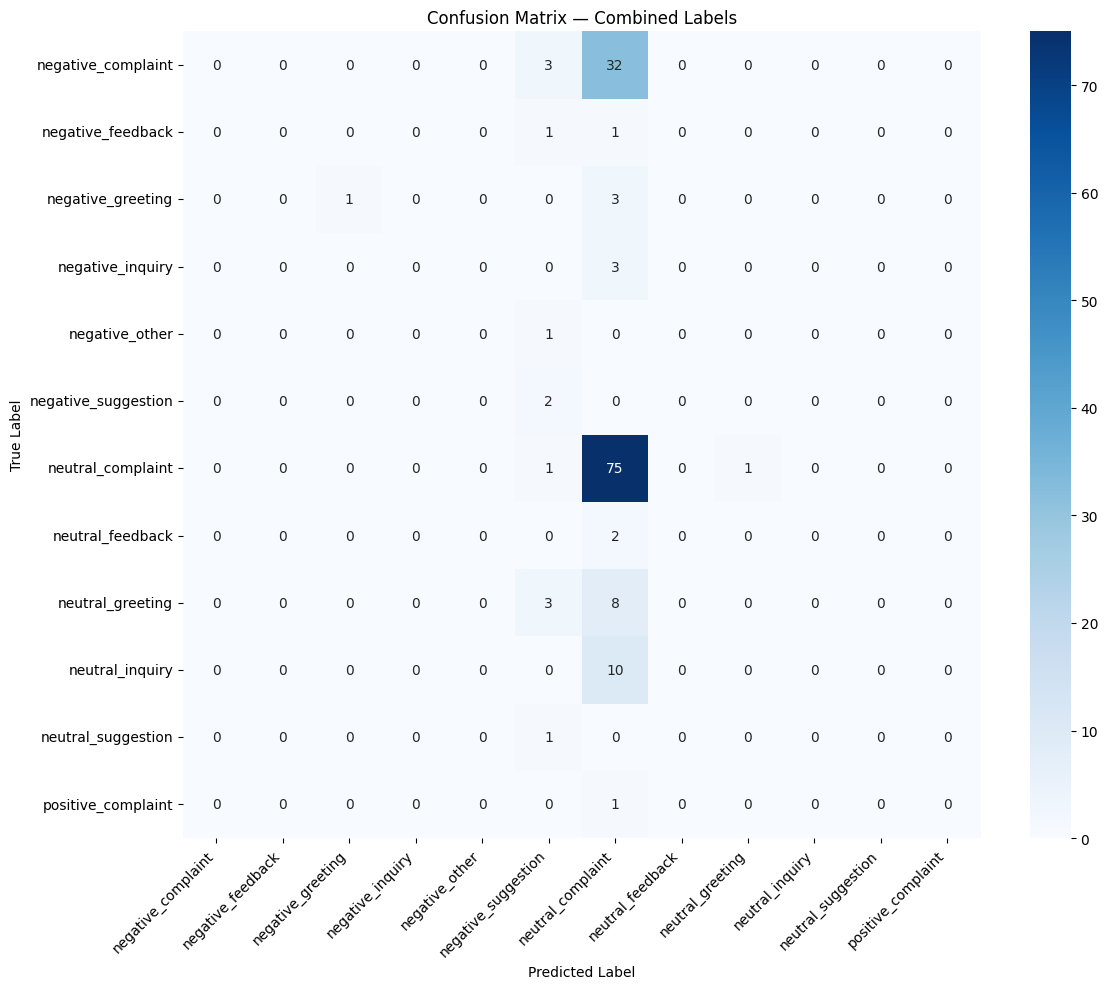

In [16]:
# ── Confusion matrix ──────────────────────────────────────────────────────
cm = confusion_matrix(val_labels, val_preds)

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES), max(6, NUM_CLASSES - 2)))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=COMBINED_CLASSES,
    yticklabels=COMBINED_CLASSES,
    ax=ax
)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('Confusion Matrix — Combined Labels')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Section 13 — Save Model & Label Mapping

In [17]:
# Save encoder + tokenizer
model.encoder.save_pretrained(MODEL_SAVE_DIR)
tokenizer.save_pretrained(MODEL_SAVE_DIR)

# Save full model state dict (best checkpoint already saved during training)
torch.save(model.state_dict(), os.path.join(MODEL_SAVE_DIR, 'combined_classifier.pt'))

# Save label mapping so inference can decode predictions
label_map = {
    'combined_classes': COMBINED_CLASSES,
    'num_classes'     : NUM_CLASSES,
    'index_to_label'  : {str(i): c for i, c in enumerate(COMBINED_CLASSES)},
    'label_to_index'  : {c: i for i, c in enumerate(COMBINED_CLASSES)},
}
with open(os.path.join(MODEL_SAVE_DIR, 'label_map.json'), 'w') as f:
    json.dump(label_map, f, indent=2)

print("Saved to:", MODEL_SAVE_DIR)
for fname in os.listdir(MODEL_SAVE_DIR):
    size_mb = os.path.getsize(os.path.join(MODEL_SAVE_DIR, fname)) / 1e6
    print(f"  {fname:<35} ({size_mb:.1f} MB)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /kaggle/working/saved_model_combined
  label_map.json                      (0.0 MB)
  combined_classifier.pt              (1114.4 MB)
  tokenizer.json                      (16.8 MB)
  model.safetensors                   (1112.2 MB)
  best_combined_model.pt              (1114.4 MB)
  config.json                         (0.0 MB)
  tokenizer_config.json               (0.0 MB)


---
## Section 14 — Inference

In [18]:
def predict(text: str, top_k: int = 3) -> dict:
    """
    Predict the combined sentiment-intent label for a given text.

    Returns:
        dict with keys:
          - text           : cleaned input
          - label          : top predicted combined label  (e.g. 'neutral_complaint')
          - sentiment      : parsed sentiment part
          - intent         : parsed intent part
          - confidence     : probability of top prediction
          - top_k          : list of (label, prob) for top-k predictions
          - all_probs      : full probability distribution
    """
    model.eval()
    cleaned = clean_text(text)
    enc = tokenizer(
        cleaned,
        max_length=MAX_LEN,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )
    with torch.no_grad():
        logits = model(
            enc['input_ids'].to(DEVICE),
            enc['attention_mask'].to(DEVICE)
        )
    probs    = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    top_idxs = probs.argsort()[::-1][:top_k]

    pred_label = COMBINED_CLASSES[top_idxs[0]]
    parts = pred_label.split('_', 1)   # split on first '_' only

    return {
        'text'      : cleaned,
        'label'     : pred_label,
        'sentiment' : parts[0] if len(parts) > 0 else '',
        'intent'    : parts[1] if len(parts) > 1 else '',
        'confidence': round(float(probs[top_idxs[0]]), 4),
        'top_k'     : [(COMBINED_CLASSES[i], round(float(probs[i]), 4)) for i in top_idxs],
        'all_probs' : {c: round(float(p), 4) for c, p in zip(COMBINED_CLASSES, probs)},
    }


def pretty_print(result: dict):
    sep = '-' * 55
    print(f"\n{sep}")
    print(f"  Text       : {result['text']}")
    print(f"  Label      : {result['label']:<20} (conf: {result['confidence']:.1%})")
    print(f"  Sentiment  : {result['sentiment']}")
    print(f"  Intent     : {result['intent']}")
    print(f"  Top predictions:")
    for lbl, prob in result['top_k']:
        bar = '█' * int(prob * 30)
        print(f"    {lbl:<25} {prob:.4f}  {bar}")
    print(sep)


# ── Test samples ──────────────────────────────────────────────────────────
test_samples = [
    "meka harima wadiyai mata refund ekk one",       # negative complaint
    "oyage service eka best godak stuthi",            # positive feedback
    "delivery date eka kawadad",                      # neutral inquiry
    "me product eka use karanne kohomad",             # neutral inquiry
    "mata oya service eka godak kamathi",             # positive feedback
    "api kohomada dannawad me situation eka",         # neutral inquiry
]

for text in test_samples:
    pretty_print(predict(text, top_k=3))


-------------------------------------------------------
  Text       : meka harima wadiyai mata refund ekk one
  Label      : neutral_complaint    (conf: 22.3%)
  Sentiment  : neutral
  Intent     : complaint
  Top predictions:
    neutral_complaint         0.2231  ██████
    negative_complaint        0.1611  ████
    neutral_greeting          0.1522  ████
-------------------------------------------------------

-------------------------------------------------------
  Text       : oyage service eka best godak stuthi
  Label      : neutral_complaint    (conf: 22.5%)
  Sentiment  : neutral
  Intent     : complaint
  Top predictions:
    neutral_complaint         0.2246  ██████
    negative_complaint        0.1608  ████
    neutral_greeting          0.1542  ████
-------------------------------------------------------

-------------------------------------------------------
  Text       : delivery date eka kawadad
  Label      : neutral_complaint    (conf: 22.7%)
  Sentiment  : neutral
 

---
## Section 15 — Batch Prediction Utility

In [19]:
def batch_predict(texts: list, batch_size: int = 32) -> pd.DataFrame:
    """
    Run inference on a list of texts efficiently (batched).
    Returns a DataFrame with columns: text, label, sentiment, intent, confidence.
    """
    model.eval()
    rows = []

    for i in range(0, len(texts), batch_size):
        batch_texts = [clean_text(t) for t in texts[i:i + batch_size]]
        enc = tokenizer(
            batch_texts,
            max_length=MAX_LEN,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        with torch.no_grad():
            logits = model(enc['input_ids'].to(DEVICE), enc['attention_mask'].to(DEVICE))
        probs = torch.softmax(logits, dim=-1).cpu().numpy()

        for j, text in enumerate(batch_texts):
            pred_idx   = probs[j].argmax()
            pred_label = COMBINED_CLASSES[pred_idx]
            parts      = pred_label.split('_', 1)
            rows.append({
                'text'      : text,
                'label'     : pred_label,
                'sentiment' : parts[0] if len(parts) > 0 else '',
                'intent'    : parts[1] if len(parts) > 1 else '',
                'confidence': round(float(probs[j][pred_idx]), 4),
            })

    return pd.DataFrame(rows)


# Example: predict on the full validation set texts
results_df = batch_predict(X_val)
print(f"Predicted {len(results_df)} samples")
results_df.head(10)

Predicted 149 samples


,text,label,sentiment,intent,confidence
0,mohuta balappane rate saamanya neethiya nowiyi...,neutral_complaint,neutral,complaint,0.2163
1,hanee danu oyath nethi thenak nehene,neutral_complaint,neutral,complaint,0.2228
2,pudumakara muspetthu munu tikak rata kata hari...,neutral_complaint,neutral,complaint,0.2198
3,gon ranja hema dekatama hota daala pora wenna ...,neutral_complaint,neutral,complaint,0.2191
4,keedenekuta hiv saha rudurayata awenika wenath...,neutral_complaint,neutral,complaint,0.2261
5,mama meeta awurudu 27 pera ma sarvodaye wada k...,negative_suggestion,negative,suggestion,0.1335
6,double tongue puttalam donkey,neutral_complaint,neutral,complaint,0.2262
7,supiriyi menna wada karuwo jayawewaa,neutral_complaint,neutral,complaint,0.2219
8,muslim ratawal nathnam sinhalaya bada ginne,neutral_complaint,neutral,complaint,0.2231
9,pala toyya thopi wage awalan gunamakuwo tika e...,neutral_complaint,neutral,complaint,0.2134


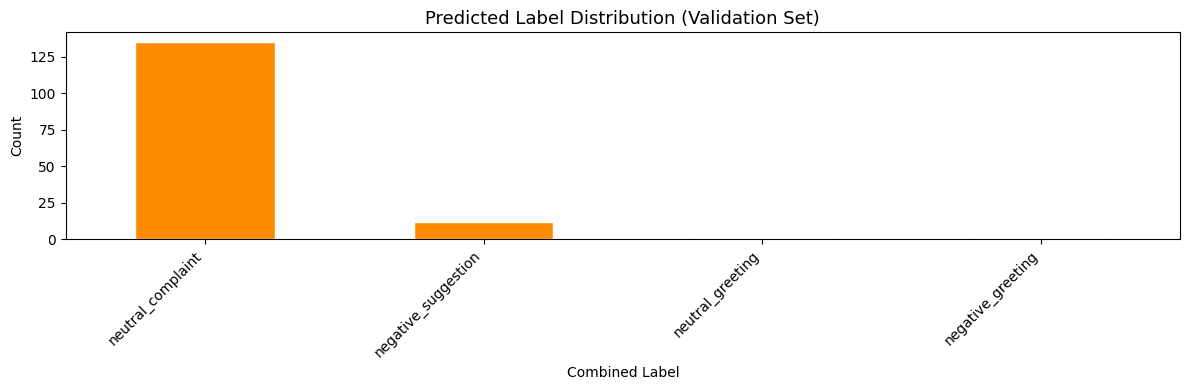

In [20]:
# Visualise predicted distribution on validation set
fig, ax = plt.subplots(figsize=(12, 4))
results_df['label'].value_counts().plot(kind='bar', ax=ax, color='darkorange', edgecolor='white')
ax.set_title('Predicted Label Distribution (Validation Set)', fontsize=13)
ax.set_xlabel('Combined Label')
ax.set_ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## Section 16 — Load Saved Model for Inference (Standalone)

Use this section independently when you want to reload the saved model without retraining.

In [21]:
import json
from transformers import AutoTokenizer, AutoModel
import torch
import torch.nn as nn

RELOAD_DIR = "/kaggle/working/saved_model_combined"
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Reload label map ──────────────────────────────────────────────────────
with open(f"{RELOAD_DIR}/label_map.json") as f:
    label_map = json.load(f)

COMBINED_CLASSES = label_map['combined_classes']
NUM_CLASSES      = label_map['num_classes']

# ── Reload tokenizer & model ──────────────────────────────────────────────
tokenizer_loaded = AutoTokenizer.from_pretrained(RELOAD_DIR)

class CombinedLabelClassifier(nn.Module):
    def __init__(self, encoder_name, num_classes, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(encoder_name)
        hidden = self.encoder.config.hidden_size
        self.trunk = nn.Sequential(
            nn.Linear(hidden, 512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512,    256), nn.GELU(), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, input_ids, attention_mask):
        cls    = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        feat   = self.trunk(cls)
        return self.classifier(feat)

model_loaded = CombinedLabelClassifier(RELOAD_DIR, NUM_CLASSES).to(DEVICE)
model_loaded.load_state_dict(torch.load(f"{RELOAD_DIR}/combined_classifier.pt", map_location=DEVICE))
model_loaded.eval()

print("Model reloaded successfully.")
print(f"Classes: {COMBINED_CLASSES}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model reloaded successfully.
Classes: ['negative_complaint', 'negative_feedback', 'negative_greeting', 'negative_inquiry', 'negative_other', 'negative_suggestion', 'neutral_complaint', 'neutral_feedback', 'neutral_greeting', 'neutral_inquiry', 'neutral_suggestion', 'positive_complaint']
